/tmp/ipykernel_1938/2432698222.py:13: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('Date', inplace=True)


95% Historical Daily VaR: -2.0907%
Maximum Drawdown: -60.9051%


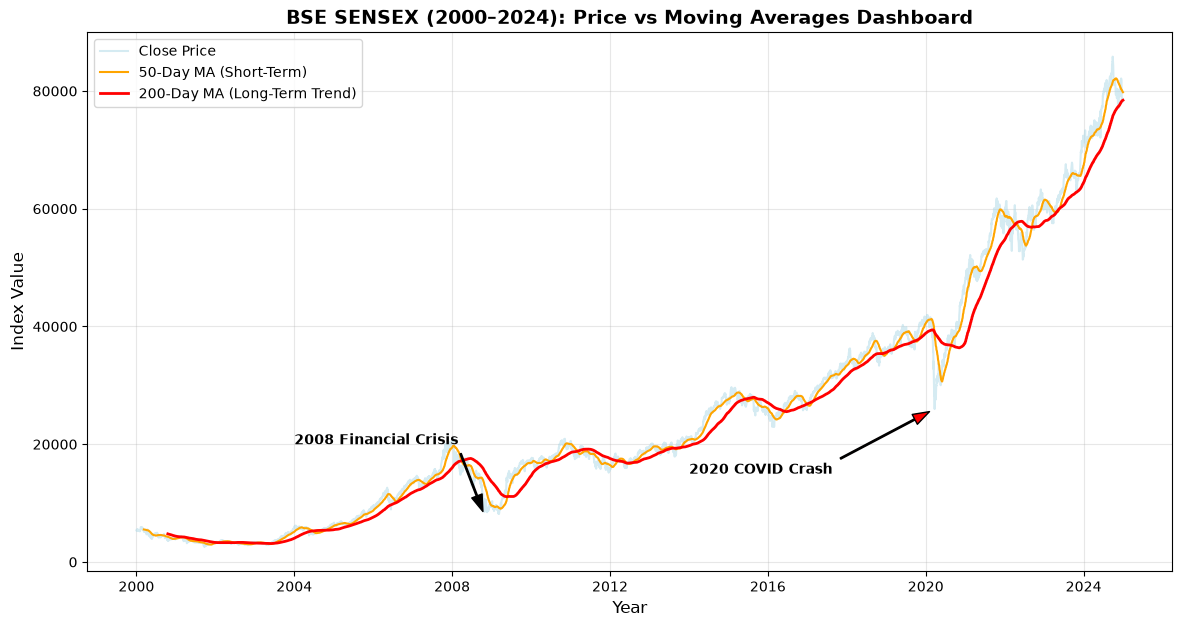

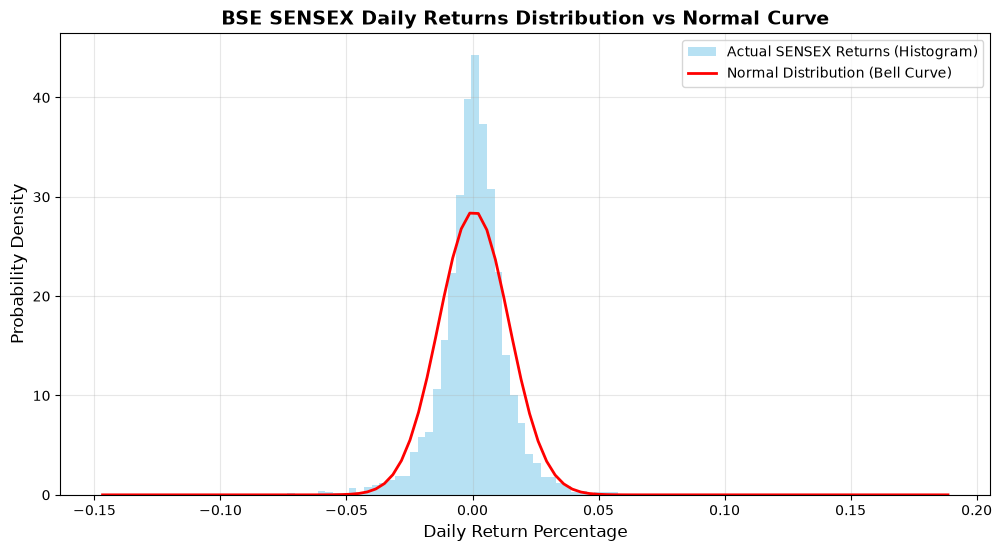

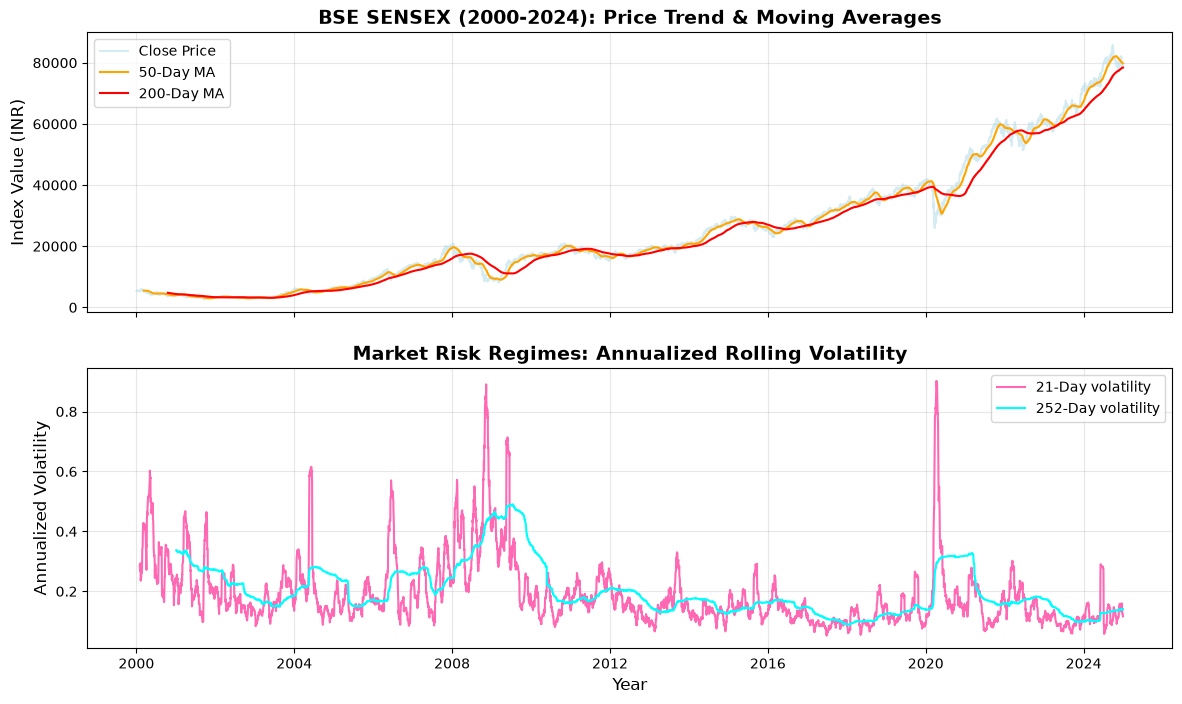

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


#  Load SENSEX dataset
df = pd.read_csv("Sensex Dataset.csv")

#  Datetime formatting & Indexing
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')
df.set_index('Date', inplace=True)

# Calculate the Daily Returns 
df['daily_returns']=df['Close'].pct_change()

#Calcualting 50-day and 200-day moving averages

df['50_day_moving_average']=df['Close'].rolling(window=50).mean()
df['200_day_moving_average']=df['Close'].rolling(window=200).mean()

# ==========================================
# PLOT 1: Time-Series Trend & Crash Annotations
# ==========================================
plt.figure(figsize=(14, 7))

plt.plot(df.index, df['Close'], label='Close Price', color='lightblue', alpha=0.5)
plt.plot(df.index, df['50_day_moving_average'], label='50-Day MA (Short-Term)', color='orange', linewidth=1.5)
plt.plot(df.index, df['200_day_moving_average'], label='200-Day MA (Long-Term Trend)', color='red', linewidth=2)

# Professional Crash Annotations belong HERE on the timeline chart!
plt.annotate('2008 Financial Crisis', 
             xy=(pd.to_datetime('2008-10-24'), 8000),  # Date and SENSEX value match!
             xytext=(pd.to_datetime('2004-01-01'), 20000), 
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=8),
             fontsize=10, fontweight='bold')

plt.annotate('2020 COVID Crash', 
             xy=(pd.to_datetime('2020-03-23'), 26000),  # COVID dip date and value!
             xytext=(pd.to_datetime('2014-01-01'), 15000), 
             arrowprops=dict(facecolor='red', shrink=0.05, width=1, headwidth=8),
             fontsize=10, fontweight='bold')

plt.title('BSE SENSEX (2000–2024): Price vs Moving Averages Dashboard', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Index Value', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)

# SAVE THE FIGURE PROFESSIONALLY
plt.savefig('sensex_trend_dashboard.png', dpi=300, bbox_inches='tight')


# ==========================================
# PLOT 2: Statistical Returns Distribution vs Bell Curve
# ==========================================
returns_clean = df['daily_returns'].dropna()
mu = returns_clean.mean()
std = returns_clean.std()

plt.figure(figsize=(12, 6))
plt.hist(returns_clean, bins=100, density=True, alpha=0.6, color='skyblue', label='Actual SENSEX Returns (Histogram)')

xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)

plt.plot(x, p, 'r-', linewidth=2, label='Normal Distribution (Bell Curve)')

plt.title('BSE SENSEX Daily Returns Distribution vs Normal Curve', fontsize=14, fontweight='bold')
plt.xlabel('Daily Return Percentage', fontsize=12)
plt.ylabel('Probability Density', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('sensex return distribution curve.png', dpi=300, bbox_inches='tight')

#=====================================================================================
# Plotting the Volatility Regime Dashboard
#=====================================================================================

df['Volatility_21D']=(df['daily_returns'].rolling(window=21).std())*np.sqrt(252)
df['Volatility_252D']=(df['daily_returns'].rolling(window=252).std())*np.sqrt(252)

fig, (ax1, ax2)=plt.subplots(2, 1, figsize=(14, 8), sharex=True)



ax1.plot(df.index, df['Close'], label='Close Price', color='lightblue', alpha=0.5)
ax1.plot(df.index, df['50_day_moving_average'], label='50-Day MA', color='orange')
ax1.plot(df.index, df['200_day_moving_average'], label='200-Day MA', color='red')


ax2.plot(df.index, df['Volatility_21D'], label='21-Day volatility', color='hotpink')
ax2.plot(df.index, df['Volatility_252D'], label='252-Day volatility', color='cyan')

ax1.set_title('BSE SENSEX (2000-2024): Price Trend & Moving Averages', fontsize=14, fontweight='bold')
ax1.set_ylabel('Index Value (INR)', fontsize=12)
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.set_title('Market Risk Regimes: Annualized Rolling Volatility', fontsize=14, fontweight='bold')
ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('Annualized Volatility', fontsize=12)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.savefig('sensex_risk_dashboard.png', dpi=300, bbox_inches='tight')

#=====================================================================================
# Value at Risk (VaR) & Maximum Drawdown (Advanced Risk Metrics)
#=====================================================================================

var_95=returns_clean.quantile(0.05)
df['Peak'] = df['Close'].cummax()
df['Drawdown'] = (df['Close'] - df['Peak']) / df['Peak']
max_drawdown = df['Drawdown'].min()
print(f"95% Historical Daily VaR: {var_95:.4%}")
print(f"Maximum Drawdown: {max_drawdown:.4%}")

In [10]:
!pip install scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 28.7 MB/s  0:00:01m0:00:0100:01

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
